In [5]:
import pandas as pd
import numpy as np

df = pd.read_csv("Data/loan.csv", low_memory=False)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (2260668, 145)


,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,...,hardship_payoff_balance_amount,hardship_last_payment_amount,disbursement_method,debt_settlement_flag,debt_settlement_flag_date,settlement_status,settlement_date,settlement_amount,settlement_percentage,settlement_term
0,NaN,NaN,2500,2500,2500.0,36 months,13.56,84.92,C,C1,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,30000,30000,30000.0,60 months,18.94,777.23,D,D2,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,5000,5000,5000.0,36 months,17.97,180.69,D,D1,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,4000,4000,4000.0,36 months,18.94,146.51,D,D2,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,30000,30000,30000.0,60 months,16.14,731.78,C,C4,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:
# Checking important columns
print("Total columns:", len(df.columns))

print("\nTarget column values:")
print(df["loan_status"].value_counts())

print("\nMissing values:")
print(df[["loan_status", "loan_amnt", "annual_inc", "int_rate", "dti"]].isnull().sum())

print("\nSelected columns:")
df[["loan_amnt", "loan_status", "annual_inc", "int_rate", "dti"]].head()

Total columns: 145

Target column values:
loan_status
Fully Paid                                             1041952
Current                                                 919695
Charged Off                                             261655
Late (31-120 days)                                       21897
In Grace Period                                           8952
Late (16-30 days)                                         3737
Does not meet the credit policy. Status:Fully Paid        1988
Does not meet the credit policy. Status:Charged Off        761
Default                                                     31
Name: count, dtype: int64

Missing values:
loan_status       0
loan_amnt         0
annual_inc        4
int_rate          0
dti            1711
dtype: int64

Selected columns:


,loan_amnt,loan_status,annual_inc,int_rate,dti
0,2500,Current,55000.0,13.56,18.24
1,30000,Current,90000.0,18.94,26.52
2,5000,Current,59280.0,17.97,10.51
3,4000,Current,92000.0,18.94,16.74
4,30000,Current,57250.0,16.14,26.35


In [7]:
# Select required columns
features = [
    "loan_amnt",
    "term",
    "int_rate",
    "installment",
    "grade",
    "emp_length",
    "home_ownership",
    "annual_inc",
    "verification_status",
    "purpose",
    "addr_state",
    "dti",
    "delinq_2yrs",
    "open_acc",
    "pub_rec",
    "revol_bal",
    "revol_util",
    "total_acc"
]

# Keep only completed loan outcomes
classification_df = df[
    df["loan_status"].isin(["Fully Paid", "Charged Off"])
][features + ["loan_status"]].copy()

# Convert loan status into binary target
classification_df["target"] = classification_df["loan_status"].map({
    "Fully Paid": 0,
    "Charged Off": 1
})

print("Classification dataset shape:", classification_df.shape)

print("\nTarget distribution:")
print(classification_df["target"].value_counts())

Classification dataset shape: (1303607, 20)

Target distribution:
target
0    1041952
1     261655
Name: count, dtype: int64


In [8]:
from sklearn.model_selection import train_test_split

# Take 15% sample
classification_sample = classification_df.groupby(
    "target", group_keys=False
).sample(frac=0.15, random_state=42)

# Separate input and output
X = classification_sample[features]
y = classification_sample["target"]

# Split into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))

Training shape: (156432, 18)
Testing shape: (39109, 18)

Training target distribution:
target
0    0.799287
1    0.200713
Name: proportion, dtype: float64


In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Separate numerical and categorical columns
numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "str"]
).columns.tolist()

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Numerical columns:", len(numeric_features))
print("Categorical columns:", len(categorical_features))
print("Preprocessing pipeline created successfully!")

Numerical columns: 11
Categorical columns: 7
Preprocessing pipeline created successfully!


In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=10,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        max_depth=15,
        oob_score=True,
        bootstrap=True,
        n_jobs=-1,
        random_state=42
    )
}

results = {}

for name, model in models.items():
    print(f"\nTraining {name}...")

    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    results[name] = {
        "Accuracy": accuracy,
        "F1 Score": f1
    }

    print("Accuracy:", accuracy)
    print("F1 Score:", f1)

    if name == "Random Forest":
        print("OOB Score:", pipeline.named_steps["classifier"].oob_score_)


Training Logistic Regression...
Accuracy: 0.8017591858651462
F1 Score: 0.10731145653425446

Training Decision Tree...
Accuracy: 0.7943184433250658
F1 Score: 0.16312942155638785

Training Random Forest...
Accuracy: 0.800608555575443
F1 Score: 0.06610778443113773
OOB Score: 0.8010189731001329


In [12]:
# Get Logistic Regression pipeline
logistic_model = models["Logistic Regression"]

logistic_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", logistic_model)
])

# Train Logistic Regression
logistic_pipeline.fit(X_train, y_train)

# First 5 test rows
probabilities = logistic_pipeline.predict_proba(X_test.iloc[:5])

predictions = logistic_pipeline.predict(X_test.iloc[:5])

# Display comparison
comparison = pd.DataFrame({
    "Actual": y_test.iloc[:5].values,
    "Probability_0": probabilities[:, 0],
    "Probability_1": probabilities[:, 1],
    "Predicted": predictions
})

comparison

,Actual,Probability_0,Probability_1,Predicted
0,1,0.851202,0.148798,0
1,0,0.819011,0.180989,0
2,0,0.796871,0.203129,0
3,0,0.845580,0.154420,0
4,0,0.465210,0.534790,1


In [13]:
# Get feature names after preprocessing
feature_names = pipeline.named_steps["preprocessor"].get_feature_names_out()

# Get Random Forest feature importance
forest_importance = pipeline.named_steps["classifier"].feature_importances_

# Display top 5 features
forest_top5 = pd.DataFrame({
    "Feature": feature_names,
    "Importance": forest_importance
}).sort_values(by="Importance", ascending=False).head(5)

forest_top5

,Feature,Importance
1,num__int_rate,0.139067
4,num__dti,0.066922
2,num__installment,0.052150
3,num__annual_inc,0.051290
8,num__revol_bal,0.048436


In [15]:
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score

# Create validation data
X_train_xgb, X_val, y_train_xgb, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

# Create XGBoost pipeline
xgb_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(
        n_estimators=500,
        max_depth=5,
        learning_rate=0.05,
        early_stopping_rounds=20,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ))
])

# Fit preprocessing separately for validation
X_train_processed = preprocessor.fit_transform(X_train_xgb)
X_val_processed = preprocessor.transform(X_val)

# Train XGBoost with validation set
xgb_model = XGBClassifier(
    n_estimators=500,
    max_depth=5,
    learning_rate=0.05,
    early_stopping_rounds=20,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(
    X_train_processed,
    y_train_xgb,
    eval_set=[(X_val_processed, y_val)],
    verbose=False
)

# Evaluate on test data
X_test_processed = preprocessor.transform(X_test)

xgb_predictions = xgb_model.predict(X_test_processed)

xgb_accuracy = accuracy_score(y_test, xgb_predictions)
xgb_f1 = f1_score(y_test, xgb_predictions)

results["XGBoost"] = {
    "Accuracy": xgb_accuracy,
    "F1 Score": xgb_f1
}

print("XGBoost Accuracy:", xgb_accuracy)
print("XGBoost F1 Score:", xgb_f1)
print("Best iteration:", xgb_model.best_iteration)

XGBoost Accuracy: 0.8022194379810274
XGBoost F1 Score: 0.115494568324757
Best iteration: 310


In [16]:
xgb_importance = xgb_model.feature_importances_

xgb_top5 = pd.DataFrame({
    "Feature": preprocessor.get_feature_names_out(),
    "Importance": xgb_importance
}).sort_values(
    by="Importance",
    ascending=False
).head(5)

xgb_top5

,Feature,Importance
13,cat__grade_A,0.128299
1,num__int_rate,0.100745
11,cat__term_ 36 months,0.059857
15,cat__grade_C,0.031195
32,cat__home_ownership_MORTGAGE,0.026473


In [17]:
regression_features = [
    "annual_inc",
    "int_rate",
    "dti",
    "delinq_2yrs",
    "open_acc",
    "pub_rec",
    "revol_bal",
    "total_acc"
]

regression_df = df[regression_features + ["loan_amnt"]].copy()

# Missing values handle panna numeric format-ku convert pannrom
for col in regression_df.columns:
    regression_df[col] = pd.to_numeric(
        regression_df[col], errors="coerce"
    )

# Dataset-la irundhu 15% sample edukkrom
regression_df = regression_df.sample(
    frac=0.15, random_state=42
)

X_reg = regression_df[regression_features]
y_reg = regression_df["loan_amnt"]

print("Dataset shape:", regression_df.shape)
print("Missing values:")
print(regression_df.isnull().sum())

Dataset shape: (339100, 9)
Missing values:
annual_inc       0
int_rate         0
dti            263
delinq_2yrs      5
open_acc         5
pub_rec          5
revol_bal        0
total_acc        5
loan_amnt        0
dtype: int64


In [18]:
from sklearn.model_selection import train_test_split

X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg,
    y_reg,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train_reg.shape)
print("Testing data:", X_test_reg.shape)

Training data: (271280, 8)
Testing data: (67820, 8)


In [19]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

reg_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

X_train_processed = reg_preprocessor.fit_transform(X_train_reg)
X_test_processed = reg_preprocessor.transform(X_test_reg)

print("Training shape:", X_train_processed.shape)
print("Testing shape:", X_test_processed.shape)

Training shape: (271280, 8)
Testing shape: (67820, 8)


In [20]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import r2_score, mean_absolute_error
import pandas as pd

reg_models = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "Lasso": Lasso(alpha=1.0)
}

reg_results = {}

for name, model in reg_models.items():
    model.fit(X_train_processed, y_train_reg)

    y_pred = model.predict(X_test_processed)

    r2 = r2_score(y_test_reg, y_pred)
    mae = mean_absolute_error(y_test_reg, y_pred)

    reg_results[name] = {
        "R2 Score": r2,
        "MAE": mae
    }

    print(name)
    print("R2 Score:", r2)
    print("MAE:", mae)
    print("-" * 30)

Linear Regression
R2 Score: 0.1928917994102578
MAE: 6499.524697592449
------------------------------
Ridge
R2 Score: 0.19289172354098727
MAE: 6499.526371026203
------------------------------
Lasso
R2 Score: 0.1928760968029556
MAE: 6499.8022909979745
------------------------------


In [21]:
coefficient_comparison = pd.DataFrame({
    "Feature": regression_features,
    "Linear Regression": reg_models["Linear Regression"].coef_,
    "Ridge": reg_models["Ridge"].coef_,
    "Lasso": reg_models["Lasso"].coef_
})

print(coefficient_comparison)

zero_count = sum(
    abs(reg_models["Lasso"].coef_) < 1e-5
)

print("\nLasso zero coefficients:", zero_count)

       Feature  Linear Regression        Ridge        Lasso
0   annual_inc        2020.755459  2020.749486  2019.762442
1     int_rate        1187.363869  1187.358460  1186.227936
2          dti          72.342401    72.342560    71.564604
3  delinq_2yrs        -312.878224  -312.876199  -311.675301
4     open_acc         119.013647   119.020234   118.945263
5      pub_rec        -424.724348  -424.722890  -423.692418
6    revol_bal        2111.185837  2111.179505  2110.819630
7    total_acc        1039.060311  1039.053575  1038.277179

Lasso zero coefficients: 0


In [22]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

cluster_features = ["loan_amnt", "annual_inc", "dti"]

cluster_df = df[cluster_features].copy()

cluster_df = cluster_df.sample(
    n=10000, random_state=42
)

cluster_df = cluster_df.apply(
    pd.to_numeric, errors="coerce"
)

cluster_df = cluster_df.fillna(
    cluster_df.median()
)

cluster_scaled = StandardScaler().fit_transform(cluster_df)

print("Clustering data shape:", cluster_scaled.shape)
print("Missing values:", cluster_df.isnull().sum().sum())

Clustering data shape: (10000, 3)
Missing values: 0


In [23]:
inertia_values = []
silhouette_values = []

for k in range(2, 9):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(cluster_scaled)

    inertia_values.append(kmeans.inertia_)

    score = silhouette_score(
        cluster_scaled, labels
    )

    silhouette_values.append(score)

    print(
        f"K = {k}, "
        f"Inertia = {kmeans.inertia_:.2f}, "
        f"Silhouette Score = {score:.4f}"
    )

K = 2, Inertia = 21337.12, Silhouette Score = 0.4056
K = 3, Inertia = 16647.05, Silhouette Score = 0.4077
K = 4, Inertia = 13518.89, Silhouette Score = 0.3758
K = 5, Inertia = 11473.39, Silhouette Score = 0.2787
K = 6, Inertia = 9940.98, Silhouette Score = 0.2807
K = 7, Inertia = 8668.13, Silhouette Score = 0.2747
K = 8, Inertia = 7681.89, Silhouette Score = 0.2855


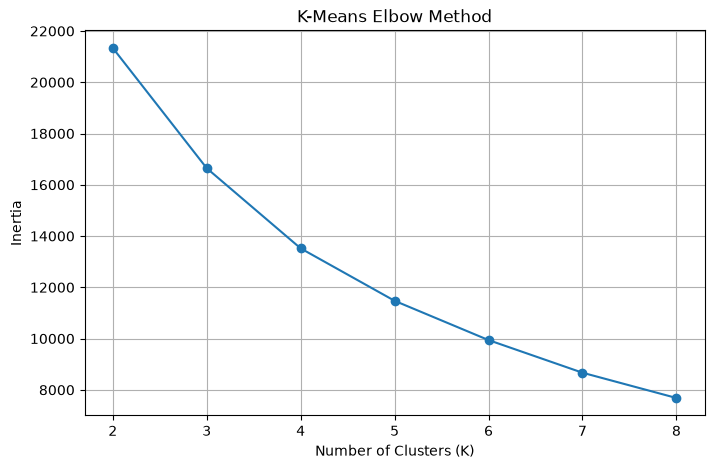

In [24]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(2, 9),
    inertia_values,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("K-Means Elbow Method")
plt.xticks(range(2, 9))
plt.grid(True)
plt.show()

In [27]:
# Remove unusual DTI values
clean_cluster_df = cluster_df[
    (cluster_df["dti"] <= 100) &
    (cluster_df["annual_inc"] > 0)
].copy()

# Scale again
cluster_scaled_clean = StandardScaler().fit_transform(
    clean_cluster_df[cluster_features]
)

# Create 3 clusters again
final_kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

clean_cluster_df["Cluster"] = final_kmeans.fit_predict(
    cluster_scaled_clean
)

# Display segment summary
print(
    clean_cluster_df.groupby("Cluster")[
        cluster_features
    ].mean().round(2)
)

print("\nCluster counts:")
print(clean_cluster_df["Cluster"].value_counts().sort_index())

         loan_amnt  annual_inc    dti
Cluster                              
0         13218.27    56855.40  28.19
1          9979.45    65058.42  12.71
2         27371.07   130750.77  16.25

Cluster counts:
Cluster
0    3280
1    4397
2    2309
Name: count, dtype: int64


In [28]:
print("XGBoost Results:")
print("Accuracy:", results["XGBoost"]["Accuracy"])
print("F1 Score:", results["XGBoost"]["F1 Score"])
print("Best Iteration:", xgb_model.best_iteration)

XGBoost Results:
Accuracy: 0.8022194379810274
F1 Score: 0.115494568324757
Best Iteration: 310


In [29]:
classification_results = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Accuracy": 0.801759,
        "F1 Score": 0.107311
    },
    {
        "Model": "Decision Tree",
        "Accuracy": 0.794318,
        "F1 Score": 0.163129
    },
    {
        "Model": "Random Forest",
        "Accuracy": 0.800609,
        "F1 Score": 0.066108
    },
    {
        "Model": "XGBoost",
        "Accuracy": 0.802219,
        "F1 Score": 0.115495
    }
])

print(classification_results)

                 Model  Accuracy  F1 Score
0  Logistic Regression  0.801759  0.107311
1        Decision Tree  0.794318  0.163129
2        Random Forest  0.800609  0.066108
3              XGBoost  0.802219  0.115495


# Lending Club Assessment – Final Findings

## Classification
- Trained Logistic Regression, Decision Tree, Random Forest and XGBoost classifiers.
- XGBoost achieved the highest accuracy of 80.22%.
- Decision Tree achieved the highest F1 score of 0.1631.
- Random Forest achieved an OOB score of 0.8010.
- XGBoost early stopping selected iteration 310.

## Regression
- Trained Linear Regression, Ridge and Lasso models to predict loan amount.
- All three models achieved an R² score of approximately 0.193.
- Linear Regression achieved the lowest MAE of approximately 6499.52.
- Lasso produced zero coefficients for 0 features.

## Clustering
- Applied K-Means clustering using loan amount, annual income and DTI.
- Tested cluster counts from K=2 to K=8.
- K=3 achieved the highest silhouette score of 0.4077.
- Identified three customer segments: higher-debt, low-debt and high-income groups.
- Removed unusual DTI values before final customer segmentation.

## Conclusion
The assessment covered supervised learning, regression and unsupervised learning. XGBoost achieved the highest classification accuracy, while Decision Tree achieved the highest F1 score. K-Means identified three customer segments based on loan amount, annual income and DTI.
